In [27]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.feature_selection import mutual_info_regression

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [28]:
df = pd.read_csv("train.csv")
df.head()

,claim_id,claim_amount,driver_age,previous_claim_count,vehicle_value,damage_severity,incident_type,repair_shop_id,phone_hash,address_id,is_fraud
0,C000001,254.29,42.0,2,11900.0,low,collision,Sb7a282e399,Pfd09f60f9e,A48656b5517,0
1,C000002,592.05,29.0,0,14600.0,low,collision,S9399315447,P8a7ff077bb,A53e94c25e5,0
2,C000007,980.14,58.0,0,17550.0,low,glass,S1bb582e486,P02246ac9cc,A84ed465d68,0
3,C000008,729.04,44.0,0,18550.0,low,collision,S7e56cdce9e,P8e162b8d1a,A46a2d8b11d,0
4,C000009,16145.05,34.0,0,29300.0,NaN,theft,S1bb582e486,Pd299199a4f,Ac638621b9b,0


Mutual info and data shape


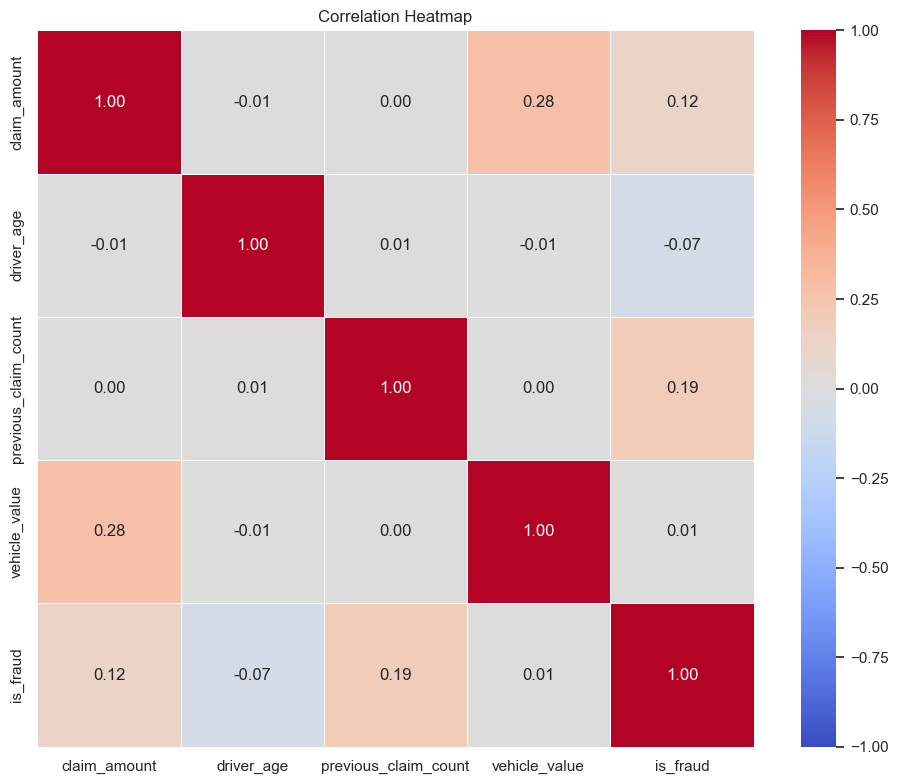

In [29]:
# Correlation matrix (numeric columns only)
corr = df.corr(numeric_only=True)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,        # show the numbers
    fmt=".2f",         # 2 decimal places
    cmap="coolwarm",   # blue = negative, red = positive
    vmin=-1, vmax=1,   # fixed scale
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

previous_claim_count    0.017435
claim_amount            0.006998
vehicle_value           0.003619
driver_age              0.002538
dtype: float64


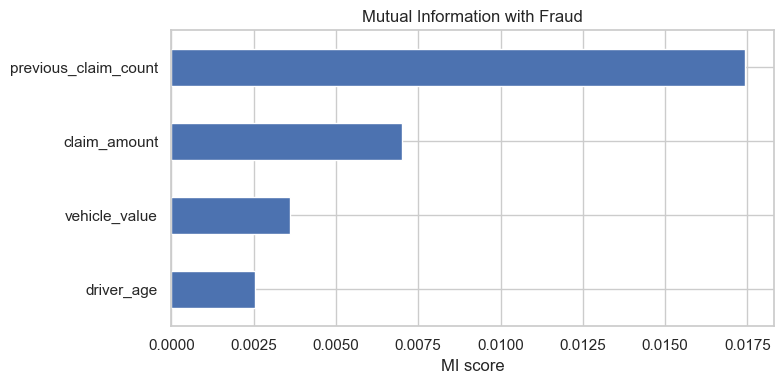

In [30]:
# Mutual Information
from sklearn.feature_selection import mutual_info_classif
features = ["claim_amount", "driver_age", "previous_claim_count", "vehicle_value", ]
target = "is_fraud"

df_2 = df[features + [target]].dropna()
df_2[target] = df[target].replace({"Yes": 1, "No": 0, "Y": 1, "N": 0, True: 1, False: 0}).astype(int)

X = df_2[features]
y = df_2[target]

mi = mutual_info_classif(X, y, random_state=42)
mi_scores = pd.Series(mi, index=features).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot(kind="barh", figsize=(8, 4), title="Mutual Information with Fraud")
plt.xlabel("MI score")
plt.tight_layout()
plt.show()

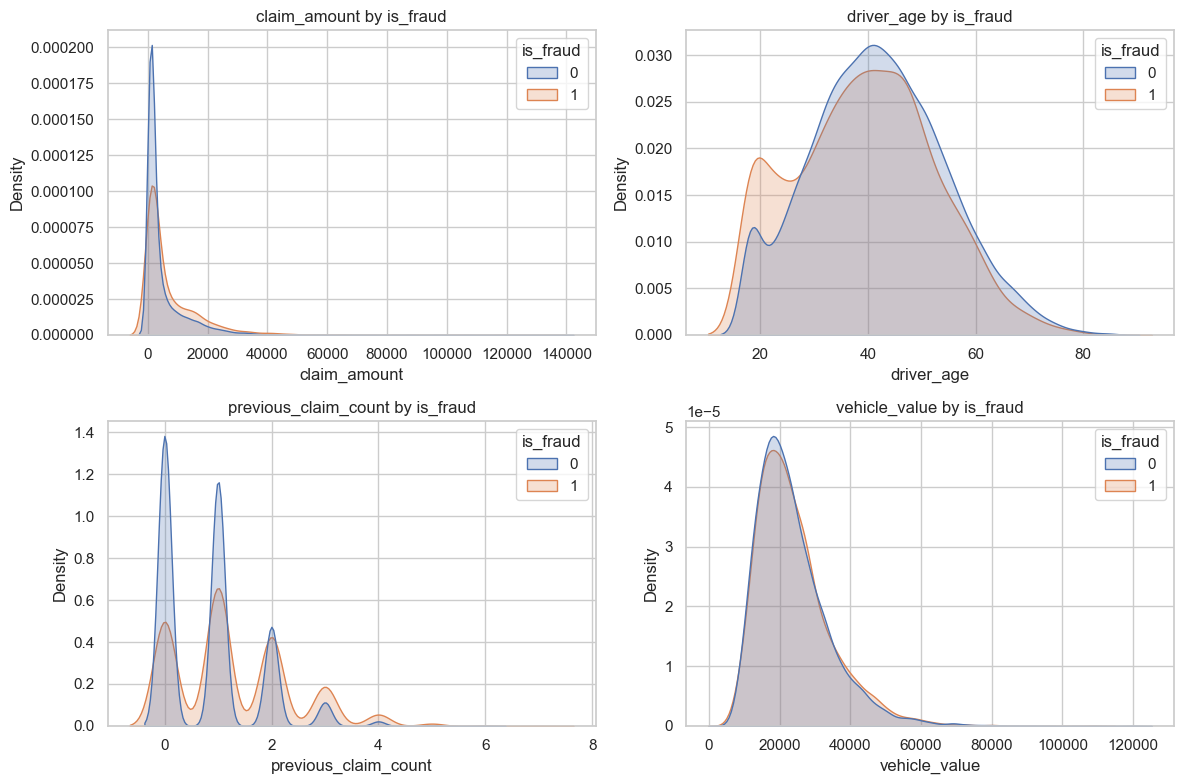

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target = "is_fraud"
numeric = ["claim_amount", "driver_age", "previous_claim_count", "vehicle_value"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), numeric):
    sns.kdeplot(data=df, x=col, hue=target, common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by {target}")
plt.tight_layout()
plt.show()

## MORE THEY CLAIM MORE THEY FRAUD?

In [32]:
vc = df["address_id"].value_counts()

print("unique addresses:", len(vc))
print("duplicated addresses:", (vc > 1).sum())
print("rows on a duplicated address:", df["address_id"].isin(vc[vc > 1].index).sum())

# Distribution of claims per address
print(vc.value_counts().sort_index())

unique addresses: 9160
duplicated addresses: 5638
rows on a duplicated address: 16478
count
1     3522
2     2842
3     1660
4      648
5      263
6       67
7       45
8       38
9       19
10      17
11      12
12       8
13       3
14       4
15       1
16       2
17       3
19       2
20       1
21       1
22       1
23       1
Name: count, dtype: int64


## PHONE VS FRAUD

In [ ]:
print("rows:", len(df))
print("unique phones:", len(vc))
print("phones used once:", (vc == 1).sum())
print("duplicated phones (2+ claims):", (vc > 1).sum())
print("extra rows (repeat of an earlier phone):", df["phone_hash"].duplicated().sum())
print("most claims on one phone:", vc.max(), " | median:", vc.median())


rows: 20000
unique phones: 9160
phones used once: 3522
duplicated phones (2+ claims): 5638
rows on a duplicated phone: 0
extra rows (repeat of an earlier phone): 10155
most claims on one phone: 23  | median: 2.0


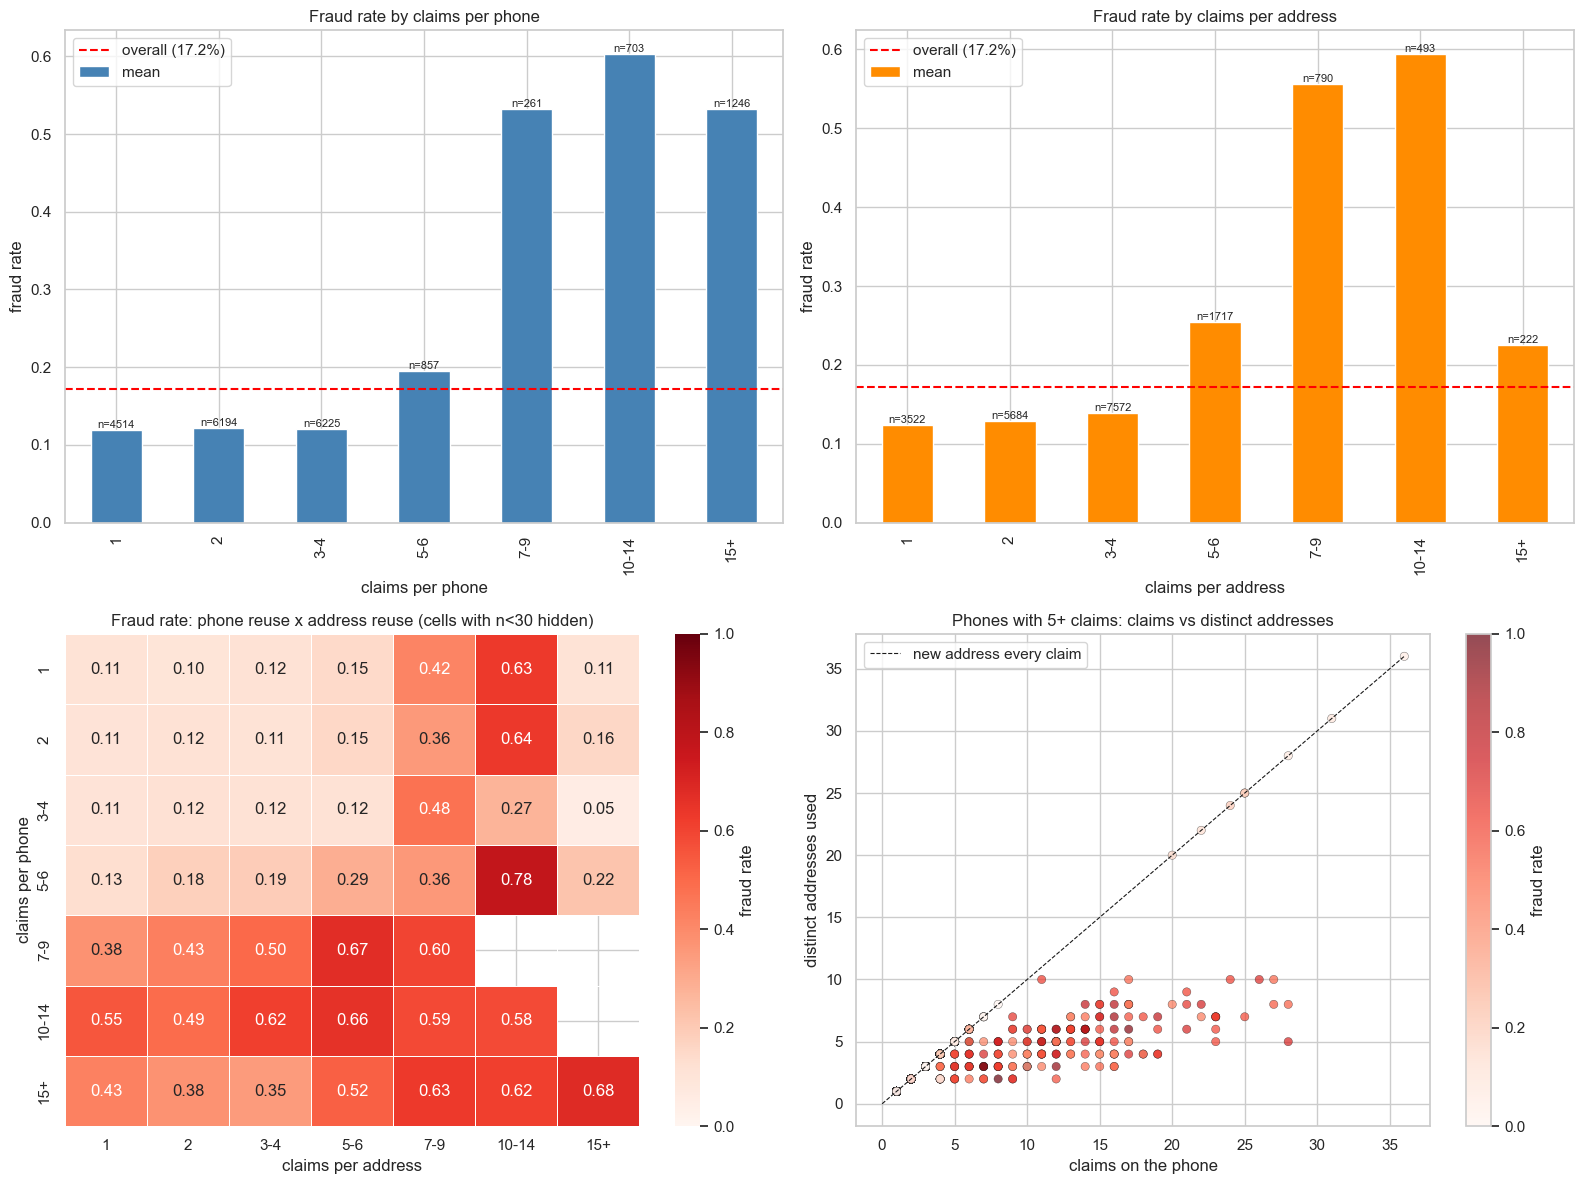

             mean  count
addr_ratio              
(0.0, 0.5]  0.605    134
(0.5, 0.9]  0.582     37
(0.9, 1.0]  0.120   9674


In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

target = "is_fraud"
base = df[target].mean()

# --- Features: how often each phone / address is reused ---
df["phone_n"] = df.groupby("phone_hash")["claim_id"].transform("count")
df["addr_n"] = df.groupby("address_id")["claim_id"].transform("count")

bins = [0, 1, 2, 4, 6, 9, 14, 100]
labels = ["1", "2", "3-4", "5-6", "7-9", "10-14", "15+"]
df["phone_bucket"] = pd.cut(df["phone_n"], bins=bins, labels=labels)
df["addr_bucket"] = pd.cut(df["addr_n"], bins=bins, labels=labels)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Phone reuse vs fraud
p = df.groupby("phone_bucket", observed=True)[target].agg(["mean", "count"])
p["mean"].plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].axhline(base, color="red", linestyle="--", label=f"overall ({base:.1%})")
axes[0, 0].set_title("Fraud rate by claims per phone")
axes[0, 0].set_xlabel("claims per phone")
axes[0, 0].set_ylabel("fraud rate")
axes[0, 0].legend()
for i, (m, c) in enumerate(zip(p["mean"], p["count"])):
    axes[0, 0].text(i, m, f"n={c}", ha="center", va="bottom", fontsize=8)

# 2. Address reuse vs fraud
a = df.groupby("addr_bucket", observed=True)[target].agg(["mean", "count"])
a["mean"].plot(kind="bar", ax=axes[0, 1], color="darkorange")
axes[0, 1].axhline(base, color="red", linestyle="--", label=f"overall ({base:.1%})")
axes[0, 1].set_title("Fraud rate by claims per address")
axes[0, 1].set_xlabel("claims per address")
axes[0, 1].set_ylabel("fraud rate")
axes[0, 1].legend()
for i, (m, c) in enumerate(zip(a["mean"], a["count"])):
    axes[0, 1].text(i, m, f"n={c}", ha="center", va="bottom", fontsize=8)

# 3. Phone x Address: fraud rate when both are reused
grid = df.pivot_table(index="phone_bucket", columns="addr_bucket",
                      values=target, aggfunc="mean", observed=True)
counts = df.pivot_table(index="phone_bucket", columns="addr_bucket",
                        values=target, aggfunc="count", observed=True)

sns.heatmap(grid, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            linewidths=0.5, ax=axes[1, 0], cbar_kws={"label": "fraud rate"})
axes[1, 0].set_title("Fraud rate: phone reuse x address reuse (cells with n<30 hidden)")
axes[1, 0].set_xlabel("claims per address")
axes[1, 0].set_ylabel("claims per phone")

# 4. Phone-address link: how many different addresses does each phone touch?
ph = (df.groupby("phone_hash")
        .agg(claims=("claim_id", "count"),
             distinct_addr=("address_id", "nunique"),
             fraud_rate=(target, "mean")))

sc = axes[1, 1].scatter(ph["claims"], ph["distinct_addr"], c=ph["fraud_rate"],
                        cmap="Reds", vmin=0, vmax=1, alpha=0.7, edgecolor="k", linewidth=0.3)
lim = ph["claims"].max()
axes[1, 1].plot([0, lim], [0, lim], "k--", linewidth=0.8, label="new address every claim")
axes[1, 1].set_title("Phones with 5+ claims: claims vs distinct addresses")
axes[1, 1].set_xlabel("claims on the phone")
axes[1, 1].set_ylabel("distinct addresses used")
axes[1, 1].legend()
plt.colorbar(sc, ax=axes[1, 1], label="fraud rate")

plt.tight_layout()
plt.show()

# Quick numeric summary of the phone-address relationship
ph["addr_ratio"] = ph["distinct_addr"] / ph["claims"]
print(ph.groupby(pd.cut(ph["addr_ratio"], [0, 0.5, 0.9, 1.0]), observed=True)["fraud_rate"]
        .agg(["mean", "count"]).round(3))

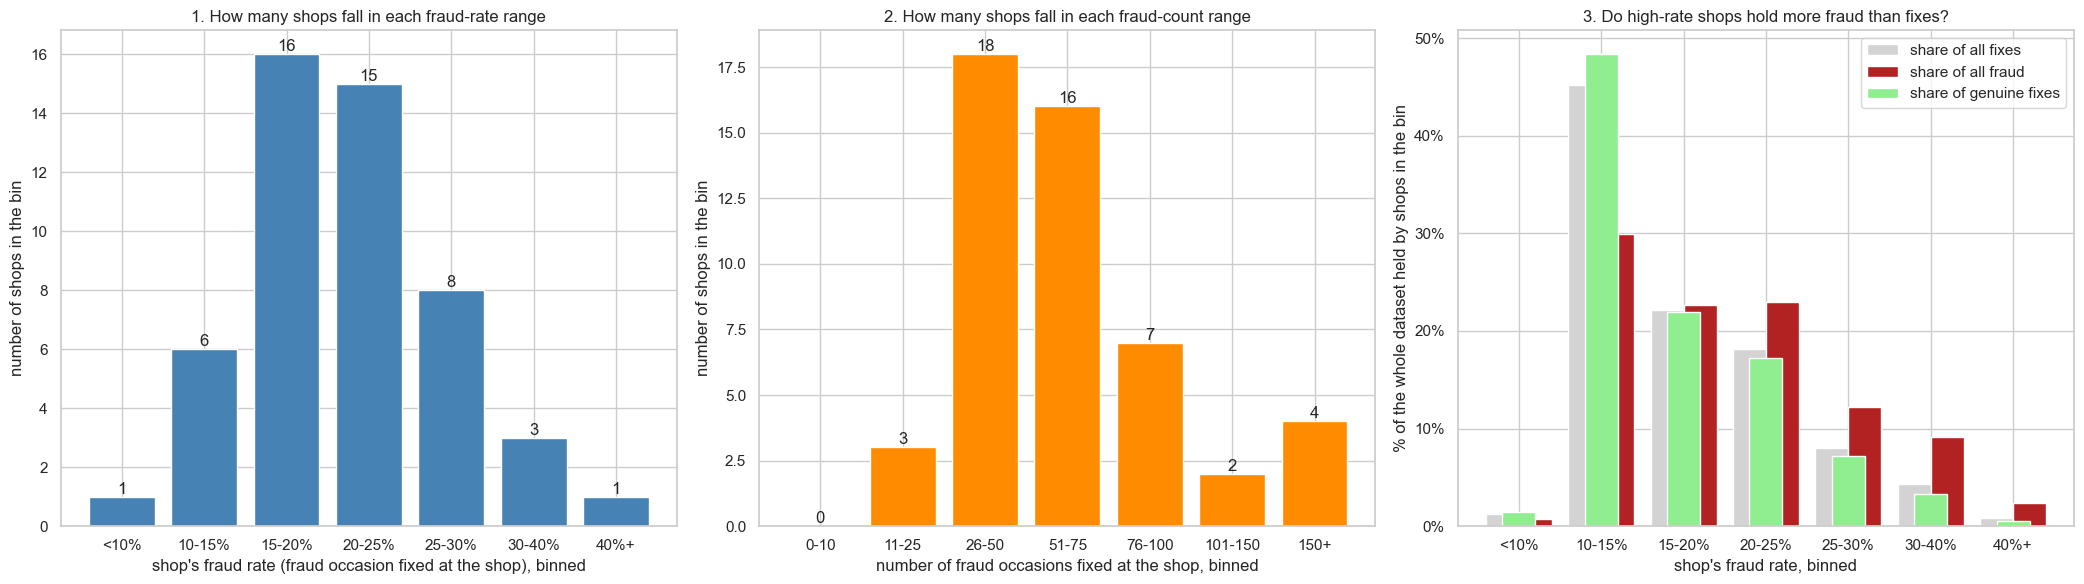

          shops  claims  fraud  share_of_fix  share_of_fraud  genuine  \
rate_bin                                                                
<10%          1     259     25         0.013           0.007      234   
10-15%        6    9041   1027         0.452           0.299     8014   
15-20%       16    4420    778         0.221           0.227     3642   
20-25%       15    3638    788         0.182           0.229     2850   
25-30%        8    1611    421         0.081           0.123     1190   
30-40%        3     860    313         0.043           0.091      547   
40%+          1     171     82         0.009           0.024       89   

          share_of_genuine  
rate_bin                    
<10%                 0.014  
10-15%               0.484  
15-20%               0.220  
20-25%               0.172  
25-30%               0.072  
30-40%               0.033  
40%+                 0.005  

Overall fraud rate: 17.2%


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "is_fraud"
base = df[target].mean()
total_fraud = df[target].sum()

shop = (df.groupby("repair_shop_id")
          .agg(claims=("claim_id", "count"),
               fraud=(target, "sum"),
               fraud_rate=(target, "mean")))

# ---------- Bins ----------
rate_bins = [0, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 1.0]
rate_labels = ["<10%", "10-15%", "15-20%", "20-25%", "25-30%", "30-40%", "40%+"]
shop["rate_bin"] = pd.cut(shop["fraud_rate"], bins=rate_bins, labels=rate_labels, include_lowest=True)

count_bins = [0, 10, 25, 50, 75, 100, 150, 1000]
count_labels = ["0-10", "11-25", "26-50", "51-75", "76-100", "101-150", "150+"]
shop["count_bin"] = pd.cut(shop["fraud"], bins=count_bins, labels=count_labels, include_lowest=True)

# Per-bin summary: how many shops, and how much of the claims / fraud they fix
by_rate = (shop.groupby("rate_bin", observed=False)
               .agg(shops=("claims", "size"), claims=("claims", "sum"), fraud=("fraud", "sum")))
by_rate["share_of_fix"] = by_rate["claims"] / len(df)
by_rate["share_of_fraud"] = by_rate["fraud"] / total_fraud
by_rate["genuine"] = by_rate["claims"] - by_rate["fraud"]
by_rate["share_of_genuine"] = by_rate["genuine"] / (len(df) - total_fraud)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Number of shops per fraud-RATE bin
ax = axes[0]
counts = shop["rate_bin"].value_counts().reindex(rate_labels)
ax.bar(rate_labels, counts.values, color="steelblue")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_xlabel("shop's fraud rate (fraud occasion fixed at the shop), binned")
ax.set_ylabel("number of shops in the bin")
ax.set_title("1. How many shops fall in each fraud-rate range")

# 2. Number of shops per fraud-COUNT bin
ax = axes[1]
counts2 = shop["count_bin"].value_counts().reindex(count_labels)
ax.bar(count_labels, counts2.values, color="darkorange")
for i, v in enumerate(counts2.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_xlabel("number of fraud occasions fixed at the shop, binned")
ax.set_ylabel("number of shops in the bin")
ax.set_title("2. How many shops fall in each fraud-count range")

# 3. Share of fixes vs share of fraud in each fraud-rate bin
ax = axes[2]
x = np.arange(len(rate_labels))
ax.bar(x - 0.2, by_rate["share_of_fix"].values, 0.4, label="share of all fixes", color="lightgray")
ax.bar(x + 0.2, by_rate["share_of_fraud"].values, 0.4, label="share of all fraud", color="firebrick")
ax.bar(x, by_rate["share_of_genuine"].values, 0.4, label="share of genuine fixes", color="lightgreen")

ax.set_xticks(x)
ax.set_xticklabels(rate_labels)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("shop's fraud rate, binned")
ax.set_ylabel("% of the whole dataset held by shops in the bin")
ax.set_title("3. Do high-rate shops hold more fraud than fixes?")
ax.legend()

plt.tight_layout()
plt.show()

print(by_rate.round(3))
print(f"\nOverall fraud rate: {base:.1%}")

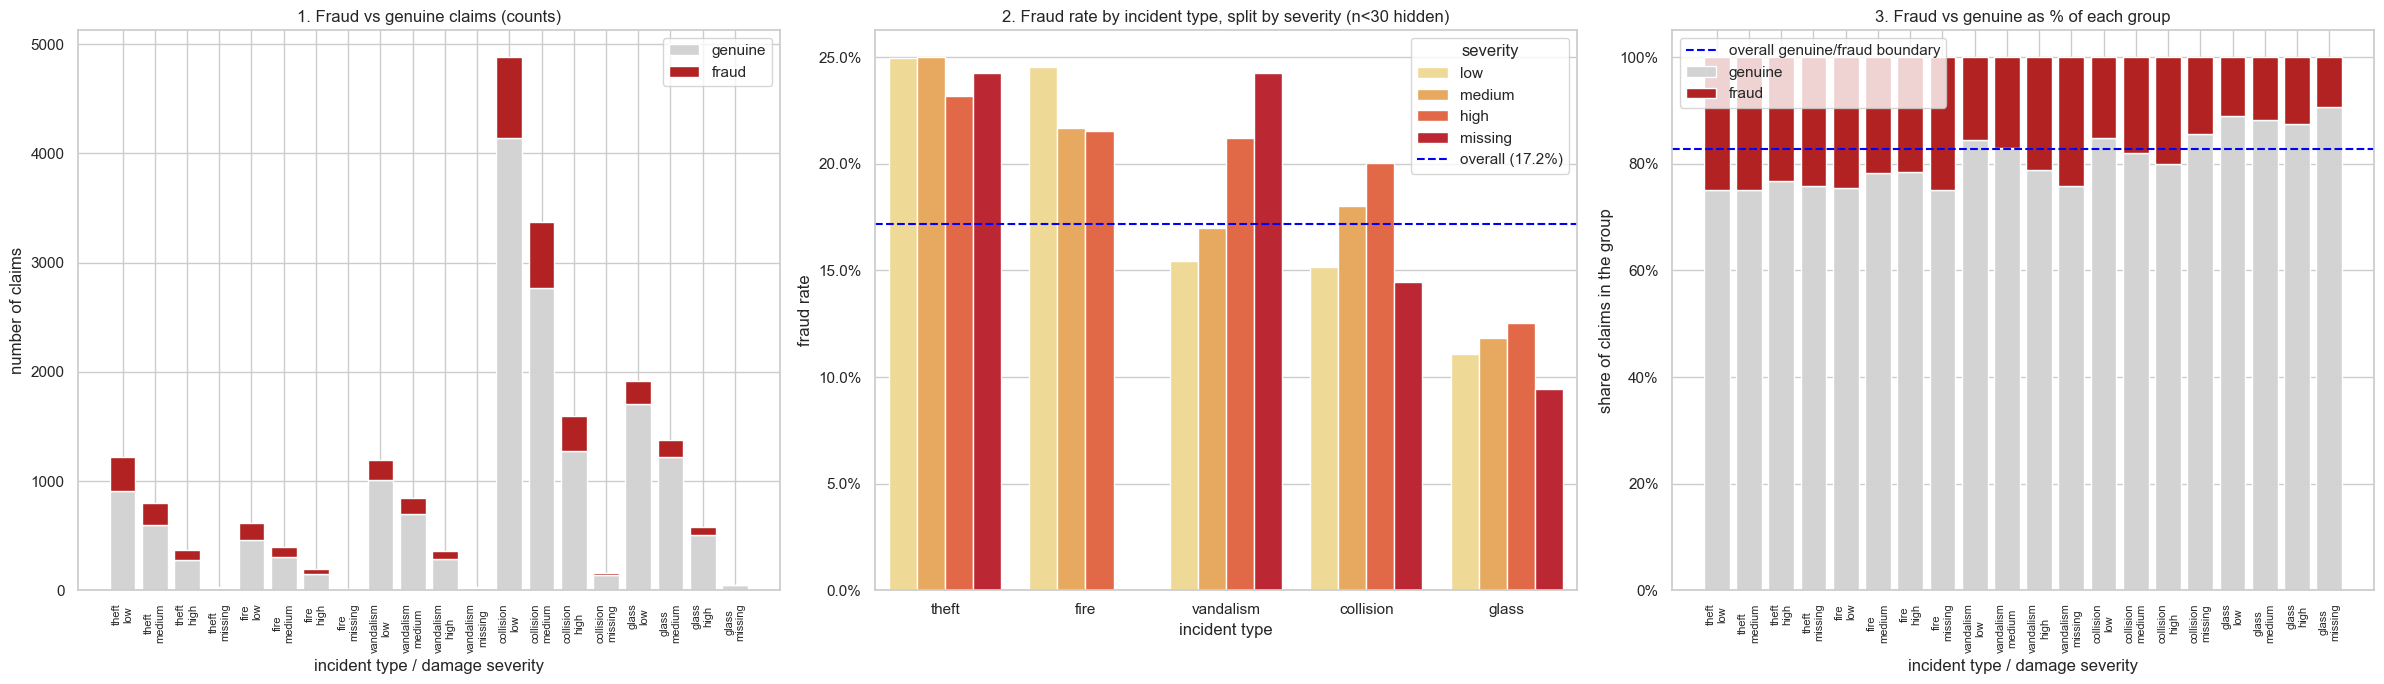

label                   fraud  genuine  total  fraud_rate
incident_type severity                                   
theft         low         304      913   1217       0.250
              medium      199      597    796       0.250
fire          missing       4       12     16       0.250
              low         151      464    615       0.246
theft         missing       8       25     33       0.242
vandalism     missing       8       25     33       0.242
theft         high         85      282    367       0.232
fire          medium       85      307    392       0.217
              high         42      153    195       0.215
vandalism     high         77      286    363       0.212
collision     high        320     1277   1597       0.200
              medium      607     2764   3371       0.180
vandalism     medium      143      698    841       0.170
              low         184     1006   1190       0.155
collision     low         741     4142   4883       0.152
              

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "is_fraud"
base = df[target].mean()
d = df.copy()

d["severity"] = pd.Categorical(
    d["damage_severity"].fillna("missing").str.lower(),
    categories=["low", "medium", "high", "missing"], ordered=True)
d["label"] = d[target].map({0: "genuine", 1: "fraud"})

inc_order = d.groupby("incident_type")[target].mean().sort_values(ascending=False).index.tolist()
sev_order = ["low", "medium", "high", "missing"]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# 1. Fraud vs genuine COUNTS for every incident type x severity combination
ax = axes[0]
counts = (d.groupby(["incident_type", "severity", "label"], observed=True)
            .size().unstack("label", fill_value=0))
counts = counts.reindex(pd.MultiIndex.from_product([inc_order, sev_order],
                                                   names=["incident_type", "severity"]),
                        fill_value=0)
x = np.arange(len(counts))
ax.bar(x, counts["genuine"], color="lightgray", label="genuine")
ax.bar(x, counts["fraud"], bottom=counts["genuine"], color="firebrick", label="fraud")
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n{s}" for i, s in counts.index], rotation=90, fontsize=8)
ax.set_xlabel("incident type / damage severity")
ax.set_ylabel("number of claims")
ax.set_title("1. Fraud vs genuine claims (counts)")
ax.legend()

# 2. Fraud RATE by incident type, one bar per severity
ax = axes[1]
rate = (d.groupby(["incident_type", "severity"], observed=True)[target]
          .agg(["mean", "count"]).reset_index())
rate = rate[rate["count"] >= 30]          # hide combinations with too few claims
sns.barplot(data=rate, x="incident_type", y="mean", hue="severity",
            order=inc_order, hue_order=sev_order, palette="YlOrRd", ax=ax)
ax.axhline(base, color="blue", linestyle="--", label=f"overall ({base:.1%})")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("incident type")
ax.set_ylabel("fraud rate")
ax.set_title("2. Fraud rate by incident type, split by severity (n<30 hidden)")
ax.legend(title="severity")

# 3. Share of each incident type that is fraud vs genuine, 100% stacked, per severity
ax = axes[2]
share = counts.div(counts.sum(axis=1), axis=0).fillna(0)
ax.bar(x, share["genuine"], color="lightgray", label="genuine")
ax.bar(x, share["fraud"], bottom=share["genuine"], color="firebrick", label="fraud")
ax.axhline(1 - base, color="blue", linestyle="--", label="overall genuine/fraud boundary")
ax.set_xticks(x)
ax.set_xticklabels([f"{i}\n{s}" for i, s in share.index], rotation=90, fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("incident type / damage severity")
ax.set_ylabel("share of claims in the group")
ax.set_title("3. Fraud vs genuine as % of each group")
ax.legend()

plt.tight_layout()
plt.show()

# Table behind the plots
table = counts.copy()
table["total"] = table["fraud"] + table["genuine"]
table["fraud_rate"] = (table["fraud"] / table["total"]).round(3)
print(table.sort_values("fraud_rate", ascending=False).to_string())

,mean,count
addr_bucket,,
1,0.123793,3522
2,0.128607,5684
3-4,0.138537,7572
5-6,0.253931,1717
7-9,0.555696,790
10-14,0.594320,493
15+,0.225225,222


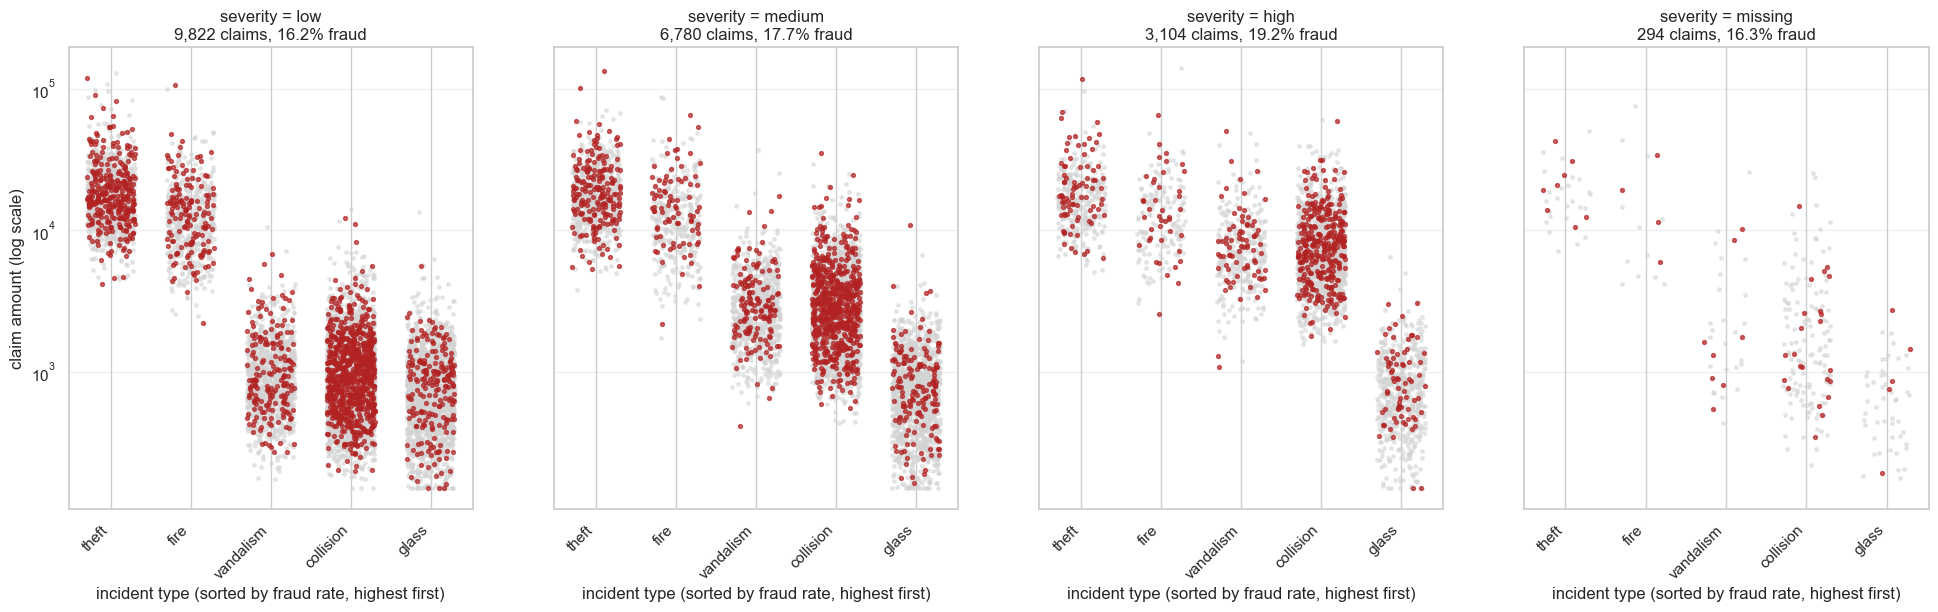

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target = "is_fraud"
d = df.copy()
d["severity"] = d["damage_severity"].fillna("missing").str.lower()

sev_order = ["low", "medium", "high", "missing"]
inc_order = d.groupby("incident_type")[target].mean().sort_values(ascending=False).index.tolist()
xpos = {inc: i for i, inc in enumerate(inc_order)}

rng = np.random.default_rng(42)
d["x"] = d["incident_type"].map(xpos) + rng.uniform(-0.3, 0.3, len(d))   # jitter so dots don't stack

fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharey=True)

for ax, sev in zip(axes, sev_order):
    s = d[d["severity"] == sev]
    gen = s[s[target] == 0]
    fra = s[s[target] == 1]

    # genuine first (background), fraud on top so it isn't hidden
    ax.scatter(gen["x"], gen["claim_amount"], s=6, color="lightgray", alpha=0.5, label="genuine")
    ax.scatter(fra["x"], fra["claim_amount"], s=8, color="firebrick", alpha=0.7, label="fraud")

    ax.set_yscale("log")
    ax.set_xticks(range(len(inc_order)))
    ax.set_xticklabels(inc_order, rotation=45, ha="right")
    ax.set_xlabel("incident type (sorted by fraud rate, highest first)")
    ax.set_title(f"severity = {sev}\n{len(s):,} claims, {s[target].mean():.1%} fraud")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("claim amount (log scale)")
a

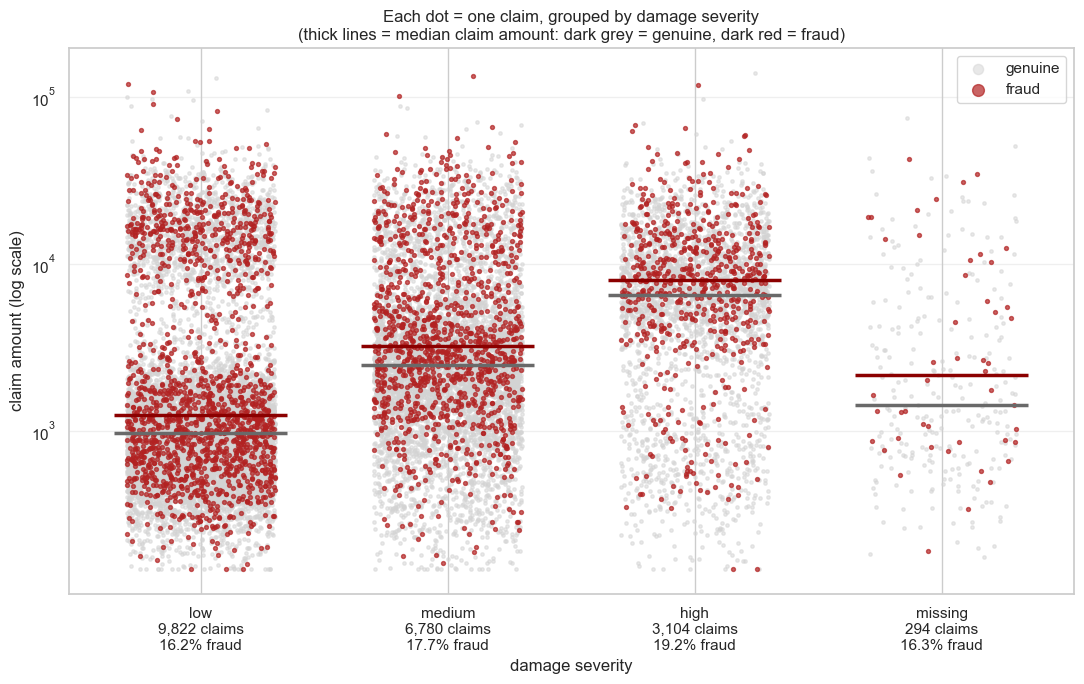

                   count  median     mean
severity is_fraud                        
high     0          2507  6554.0   8279.0
         1           597  8029.0  10610.0
low      0          8230   970.0   3702.0
         1          1592  1253.0   6267.0
medium   0          5583  2478.0   4879.0
         1          1197  3220.0   7147.0
missing  0           246  1427.0   4822.0
         1            48  2162.0   7002.0


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target = "is_fraud"
d = df.copy()
d["severity"] = d["damage_severity"].fillna("missing").str.lower()

sev_order = ["low", "medium", "high", "missing"]
xpos = {s: i for i, s in enumerate(sev_order)}

rng = np.random.default_rng(42)
d["x"] = d["severity"].map(xpos) + rng.uniform(-0.3, 0.3, len(d))   # jitter so dots don't stack

gen = d[d[target] == 0]
fra = d[d[target] == 1]

fig, ax = plt.subplots(figsize=(11, 7))

# genuine first (background), fraud on top so it isn't hidden
ax.scatter(gen["x"], gen["claim_amount"], s=6, color="lightgray", alpha=0.5, label="genuine")
ax.scatter(fra["x"], fra["claim_amount"], s=8, color="firebrick", alpha=0.7, label="fraud")

# median claim amount per severity and class
for sev in sev_order:
    for cls, col in [(0, "dimgray"), (1, "darkred")]:
        med = d[(d["severity"] == sev) & (d[target] == cls)]["claim_amount"].median()
        i = xpos[sev]
        ax.hlines(med, i - 0.35, i + 0.35, color=col, linewidth=2.5, zorder=4)

ax.set_yscale("log")
ax.set_xticks(range(len(sev_order)))
ax.set_xticklabels([f"{s}\n{(d['severity'] == s).sum():,} claims\n{d.loc[d['severity'] == s, target].mean():.1%} fraud"
                    for s in sev_order])
ax.set_xlabel("damage severity")
ax.set_ylabel("claim amount (log scale)")
ax.set_title("Each dot = one claim, grouped by damage severity\n(thick lines = median claim amount: dark grey = genuine, dark red = fraud)")
ax.grid(axis="y", alpha=0.3)
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

# Numbers behind the plot
print(d.groupby(["severity", target])["claim_amount"]
        .agg(["count", "median", "mean"]).round(0))

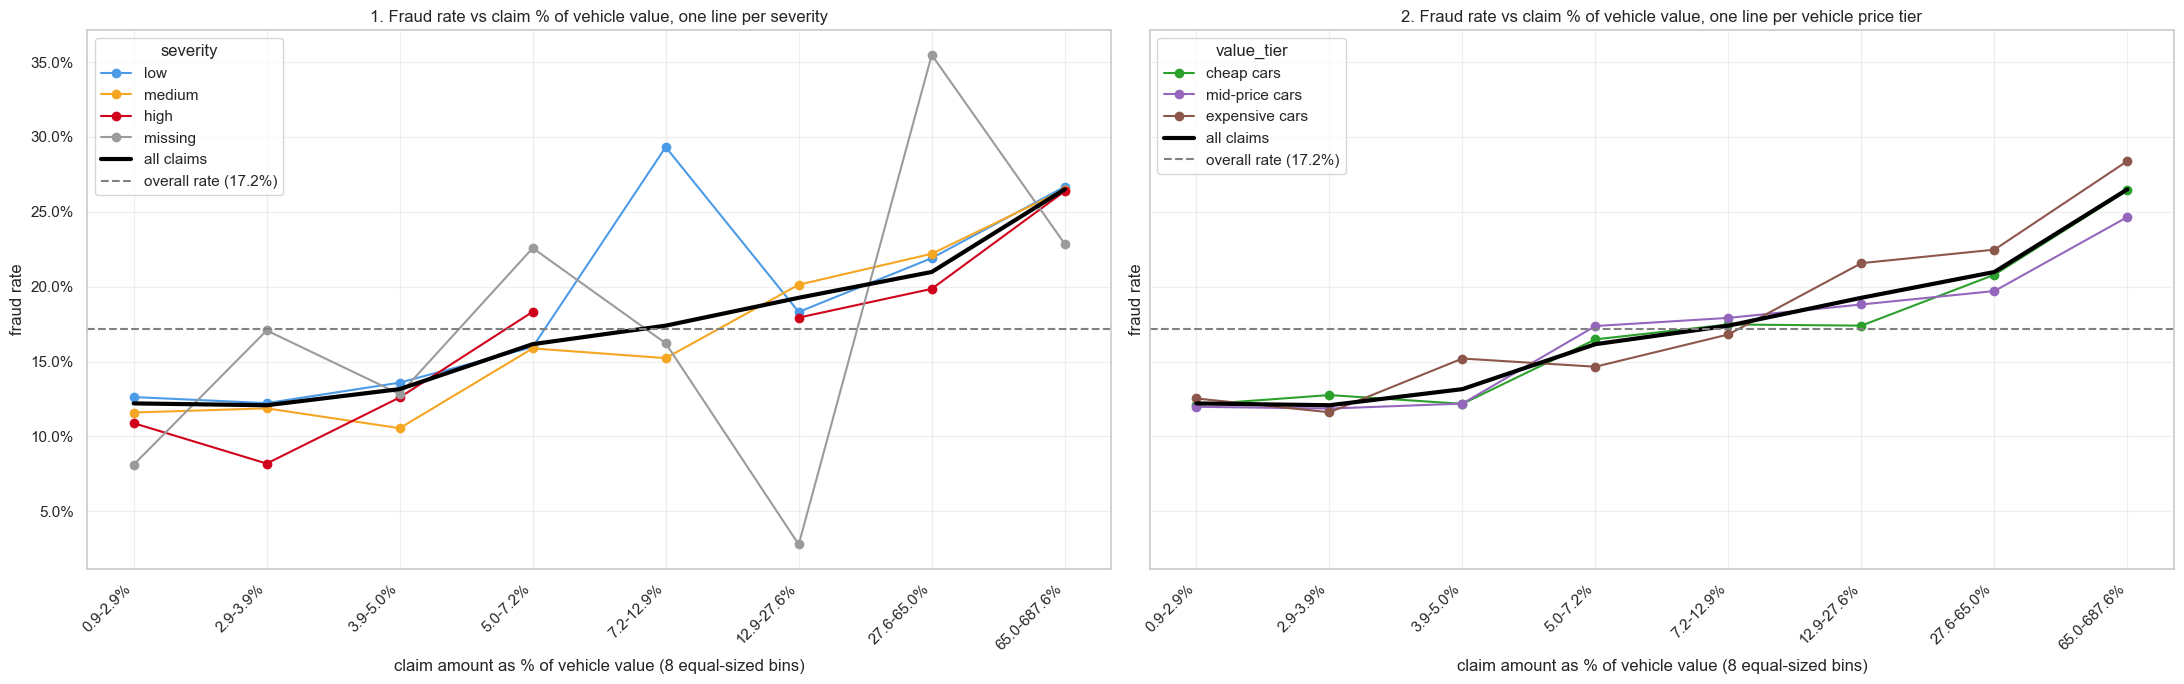

Claims per point (severity):
 severity      low  medium  high  missing
pct_bin                                 
0.9-2.9%     1687     509   193       37
2.9-3.9%     1997     278   110       41
3.9-5.0%     1965     294   127       39
5.0-7.2%     1716     548   131       31
7.2-12.9%     341    2023    25       37
12.9-27.6%     71    1699   619       36
27.6-65.0%    598     437  1360       31
65.0-687.6%  1166     789   436       35 

Fraud rate by claim % bin:
               mean  count
pct_bin                  
0.9-2.9%     0.122   2426
2.9-3.9%     0.121   2426
3.9-5.0%     0.132   2425
5.0-7.2%     0.162   2426
7.2-12.9%    0.174   2426
12.9-27.6%   0.193   2425
27.6-65.0%   0.210   2426
65.0-687.6%  0.265   2426 

Median claim % of vehicle value:
 is_fraud
0     6.3
1    12.0
Name: claim_pct, dtype: float64


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "is_fraud"
base = df[target].mean()
d = df.copy()

sev_order = ["low", "medium", "high", "missing"]
d["severity"] = pd.Categorical(d["damage_severity"].fillna("missing").str.lower(),
                               categories=sev_order, ordered=True)

# Claim as a % of vehicle value (rows with no vehicle_value can't be used here)
d = d.dropna(subset=["vehicle_value"]).copy()
d = d[d["vehicle_value"] > 0]
d["claim_pct"] = d["claim_amount"] / d["vehicle_value"] * 100

# 8 equal-sized bins of claim %, labelled with the range
q = 8
_, edges = pd.qcut(d["claim_pct"], q=q, retbins=True, duplicates="drop")
labels = [f"{edges[i]:.1f}-{edges[i+1]:.1f}%" for i in range(len(edges) - 1)]
d["pct_bin"] = pd.qcut(d["claim_pct"], q=q, labels=labels, duplicates="drop")

# Vehicle price tier (3 equal-sized groups)
d["value_tier"] = pd.qcut(d["vehicle_value"], q=3, labels=["cheap cars", "mid-price cars", "expensive cars"])

MIN_N = 30   # hide points built on fewer claims than this

def lines(ax, group_col, order, colors, title):
    rate = d.pivot_table(index="pct_bin", columns=group_col, values=target, aggfunc="mean", observed=True)
    cnt = d.pivot_table(index="pct_bin", columns=group_col, values=target, aggfunc="count", observed=True)
    for g in order:
        ax.plot(range(len(rate)), rate[g].where(cnt[g] >= MIN_N).values,
                marker="o", color=colors[g], label=str(g))
    overall = d.groupby("pct_bin", observed=True)[target].mean()
    ax.plot(range(len(overall)), overall.values, color="black", linewidth=3, label="all claims")
    ax.axhline(base, color="gray", linestyle="--", label=f"overall rate ({base:.1%})")
    ax.set_xticks(range(len(rate.index)))
    ax.set_xticklabels(rate.index.astype(str), rotation=45, ha="right")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("claim amount as % of vehicle value (8 equal-sized bins)")
    ax.set_ylabel("fraud rate")
    ax.set_title(title)
    ax.legend(title=group_col)
    ax.grid(alpha=0.3)
    return cnt

fig, axes = plt.subplots(1, 2, figsize=(22, 7), sharey=True)

sev_colors = {"low": "#4c9be8", "medium": "#f5a623", "high": "#d0021b", "missing": "#9b9b9b"}
cnt_sev = lines(axes[0], "severity", sev_order, sev_colors,
                "1. Fraud rate vs claim % of vehicle value, one line per severity")

tier_order = ["cheap cars", "mid-price cars", "expensive cars"]
tier_colors = {"cheap cars": "#2ca02c", "mid-price cars": "#9467bd", "expensive cars": "#8c564b"}
cnt_tier = lines(axes[1], "value_tier", tier_order, tier_colors,
                 "2. Fraud rate vs claim % of vehicle value, one line per vehicle price tier")

plt.tight_layout()
plt.show()

# Numbers
print("Claims per point (severity):\n", cnt_sev.astype(int), "\n")
print("Fraud rate by claim % bin:\n",
      d.groupby("pct_bin", observed=True)[target].agg(["mean", "count"]).round(3), "\n")
print("Median claim % of vehicle value:\n",
      d.groupby(target)["claim_pct"].median().round(1))